In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


movies_raw = pd.read_csv('imdb_top_250_movies.csv')

# Section 1: What's the dataset we're using?

## 1.1 What are its columns?

In [18]:
movies_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   250 non-null    str    
 1   url                  250 non-null    str    
 2   primaryTitle         250 non-null    str    
 3   originalTitle        250 non-null    str    
 4   type                 250 non-null    str    
 5   parentImdbId         0 non-null      float64
 6   description          250 non-null    str    
 7   primaryImage         250 non-null    str    
 8   thumbnails           250 non-null    str    
 9   trailer              244 non-null    str    
 10  contentRating        244 non-null    str    
 11  startYear            250 non-null    int64  
 12  endYear              0 non-null      float64
 13  releaseDate          250 non-null    str    
 14  interests            250 non-null    str    
 15  countriesOfOrigin    250 non-null    str    
 16  e

## Example of data

In [19]:
movies_raw.head(1)

,id,url,primaryTitle,originalTitle,type,parentImdbId,description,primaryImage,thumbnails,trailer,...,filmingLocations,productionCompanies,budget,grossWorldwide,genres,isAdult,runtimeMinutes,averageRating,numVotes,metascore
0,tt0111161,https://www.imdb.com/title/tt0111161/,The Shawshank Redemption,The Shawshank Redemption,movie,NaN,After a banker is sentenced to life in Shawsha...,https://m.media-amazon.com/images/M/MV5BMDAyY2...,[{'url': 'https://m.media-amazon.com/images/M/...,https://www.youtube.com/watch?v=xyXX8LXiNJ4,...,"['Butler, Ohio, USA']","[{'id': 'co0040620', 'name': 'Castle Rock Ente...",25000000.0,29425588.0,['Drama'],False,142,9.3,3254168,82.0


# 2. Data Cleaning
do we need everything? NO! Let's cut the useless data! 
and make a clean movies datafram with only the columns we're interested in

In [20]:
movies = movies_raw[["id", "primaryTitle","type","filmingLocations","productionCompanies", "budget","grossWorldwide", "genres", "isAdult", "runtimeMinutes", "averageRating", "numVotes", "metascore"]]

In [21]:
movies.head(3)

,id,primaryTitle,type,filmingLocations,productionCompanies,budget,grossWorldwide,genres,isAdult,runtimeMinutes,averageRating,numVotes,metascore
0,tt0111161,The Shawshank Redemption,movie,"['Butler, Ohio, USA']","[{'id': 'co0040620', 'name': 'Castle Rock Ente...",25000000.0,2.942559e+07,['Drama'],False,142,9.3,3254168,82.0
1,tt0068646,The Godfather,movie,"[""Forza d'Agrò, Messina, Sicily, Italy""]","[{'id': 'co0023400', 'name': 'Paramount Pictur...",6000000.0,2.509356e+08,"['Crime', 'Drama']",False,175,9.2,2265838,100.0
2,tt0468569,The Dark Knight,movie,"['Chicago, Illinois, USA']","[{'id': 'co0002663', 'name': 'Warner Bros.'}, ...",185000000.0,1.008481e+09,"['Crime', 'Thriller']",False,152,9.1,3240614,85.0


Are there null values that could create problems?

In [22]:
movies = movies.dropna()
movies = movies[movies["grossWorldwide"] > 0]

Budget column contains data in different currencies without noting which one is used. 
The data is for this reason useless, let's drop it

In [23]:
movies = movies.drop('budget', axis=1)

# 3. Analysis

## Goal: Differences between relative low vs high budget movies in  the IMDB top 250

We define low and high budget as the 25 movies with the most and least revenues in list

In [24]:

least_revenues = movies.nsmallest(25, "grossWorldwide")
least_revenues.head(3)
least_revenues.nsmallest(5, "grossWorldwide")  

,id,primaryTitle,type,filmingLocations,productionCompanies,grossWorldwide,genres,isAdult,runtimeMinutes,averageRating,numVotes,metascore
228,tt0047296,On the Waterfront,movie,['St Peter and St Paul Church - 400 Hudson Str...,"[{'id': 'co0014351', 'name': 'Columbia Picture...",3768.0,"['Crime', 'Drama', 'Thriller']",False,108,8.1,181846,91.0
65,tt0051201,Witness for the Prosecution,movie,['Metro-Goldwyn-Mayer Studios - 10202 W. Washi...,"[{'id': 'co0134950', 'name': 'Edward Small Pro...",8739.0,"['Crime', 'Drama', 'Mystery']",False,116,8.4,165235,76.0
66,tt0050825,Paths of Glory,movie,"['Schloß Schleißheim, Oberschleißheim, Bavaria...","[{'id': 'co0068126', 'name': 'Bryna Production...",9587.0,"['Drama', 'War']",False,88,8.4,243441,90.0
134,tt0055031,Judgment at Nuremberg,movie,"['former Reichsparteitag area, Nuremberg, Bava...","[{'id': 'co0160497', 'name': 'Roxlom Films Inc...",12180.0,"['Drama', 'History', 'War']",False,179,8.3,98855,60.0
5,tt0050083,12 Angry Men,movie,['New York County Courthouse - 60 Centre Stree...,"[{'id': 'co0032902', 'name': 'Orion-Nova Produ...",15647.0,"['Crime', 'Drama']",False,96,9.0,1008320,97.0


In [25]:
most_revenues = movies.nlargest(25, "grossWorldwide")
most_revenues.head(3)

,id,primaryTitle,type,filmingLocations,productionCompanies,grossWorldwide,genres,isAdult,runtimeMinutes,averageRating,numVotes,metascore
73,tt4154796,Avengers: Endgame,movie,"['Durham Cathedral, The College, Durham, Count...","[{'id': 'co0051941', 'name': 'Marvel Studios'}]",2.938420e+09,"['Action', 'Adventure', 'Sci-Fi']",False,181,8.4,1500837,78.0
58,tt4154756,Avengers: Infinity War,movie,"['Cockburn Street, Edinburgh, City of Edinburg...","[{'id': 'co0051941', 'name': 'Marvel Studios'}...",2.052415e+09,"['Action', 'Adventure', 'Sci-Fi']",False,149,8.4,1418274,68.0
207,tt10872600,Spider-Man: No Way Home,movie,['Iceland'],"[{'id': 'co0014351', 'name': 'Columbia Picture...",1.921426e+09,"['Action', 'Adventure', 'Fantasy']",False,148,8.1,1082435,71.0


## Let's compare their features!
### which one has more adult films?

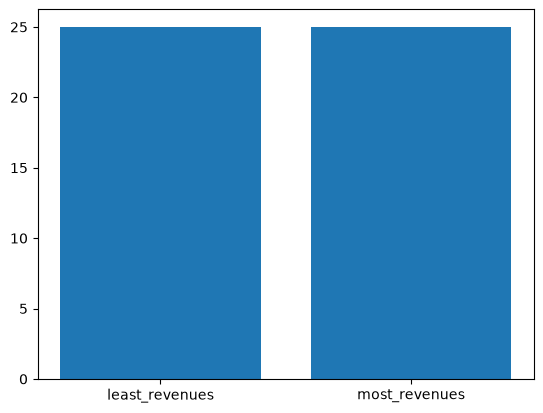

In [26]:
least_revenues_count =(least_revenues["isAdult"]==0 ).sum()
most_revenues_counts =(most_revenues["isAdult"]==0).sum()
plt.bar(["least_revenues", "most_revenues"], [least_revenues_count, most_revenues_counts])
plt.show()

Every movie is made for adults only

## How does the ratings differ between incomes?

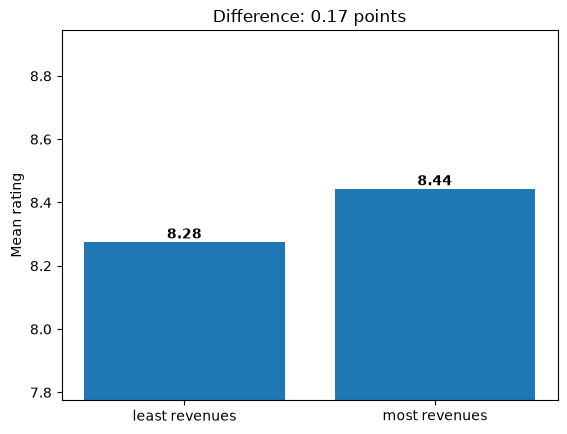

In [27]:
mean_least_revenues = least_revenues["averageRating"].mean()
mean_most_revenues = most_revenues["averageRating"].mean()

means = [mean_least_revenues, mean_most_revenues]
labels = ["least revenues", "most revenues"]

plt.bar(labels, means)
plt.ylim(min(means) - 0.5, max(means) + 0.5)   # zoom in on the difference

for i, m in enumerate(means):
    plt.text(i, m, f"{m:.2f}", ha="center", va="bottom", fontweight="bold")

plt.ylabel("Mean rating")
plt.title(f"Difference: {abs(mean_most_revenues - mean_least_revenues):.2f} points")
plt.show()

revenues are relatively rapresentative of the rating 

## But are there exceptions?

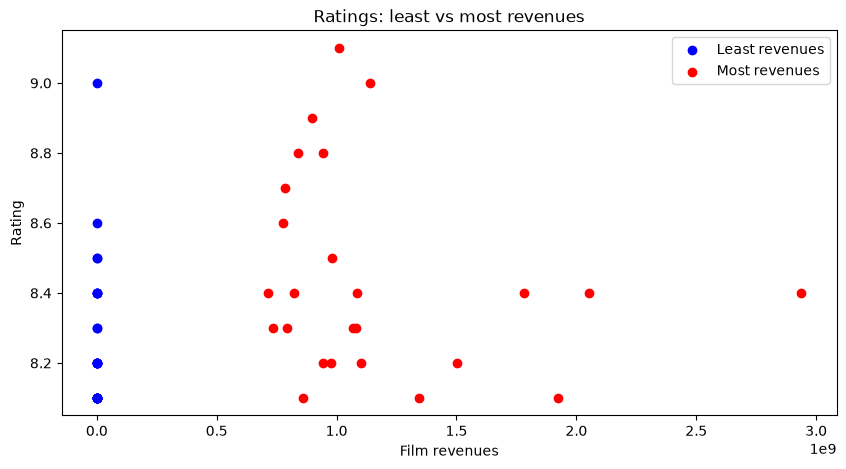

In [28]:
plt.figure(figsize=(10, 5))

# x = revenues, y = its rating
plt.scatter(least_revenues["grossWorldwide"], least_revenues["averageRating"], color="blue", label="Least revenues")
plt.scatter(most_revenues["grossWorldwide"], most_revenues["averageRating"], color="red", label="Most revenues")

plt.xlabel("Film revenues")
plt.ylabel("Rating")
plt.title("Ratings: least vs most revenues")
plt.legend()
plt.show()

The least revenues stand in a very little amount of revenues mostly because they come out in the middle of 20th century, also during war period. This led to an uninflactionated low amount of revenues, still the public ratings are very high

- same thing with metascore
- comparison bw that graph and the rating one

In [29]:
## What about the critique score?

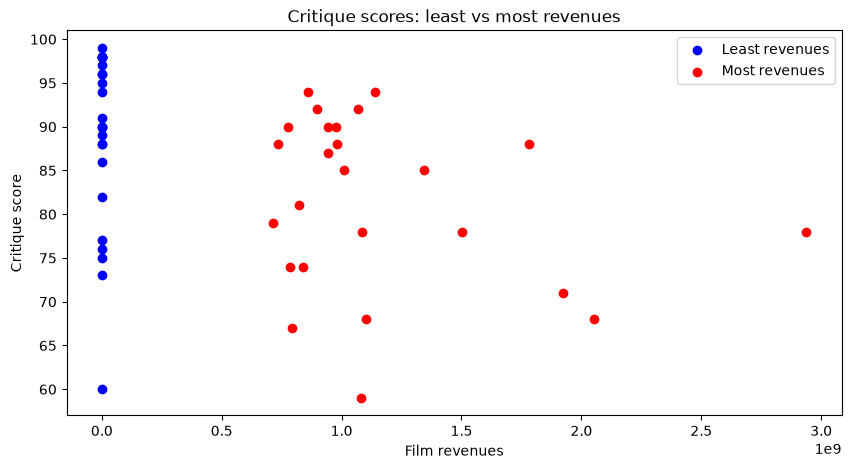

In [30]:
plt.figure(figsize=(10, 5))

# x = revenues, y = its critique score
plt.scatter(least_revenues["grossWorldwide"], least_revenues["metascore"], color="blue", label="Least revenues")
plt.scatter(most_revenues["grossWorldwide"], most_revenues["metascore"], color="red", label="Most revenues")

plt.xlabel("Film revenues")
plt.ylabel("Critique score")
plt.title("Critique scores: least vs most revenues")
plt.legend()
plt.show()

## How does the Viewer score diffear with the Critique score? (Let's keep account of only most revenues because their data is more meaningful)
To standardize data metascore is converted in 1-10 instead of 1-100

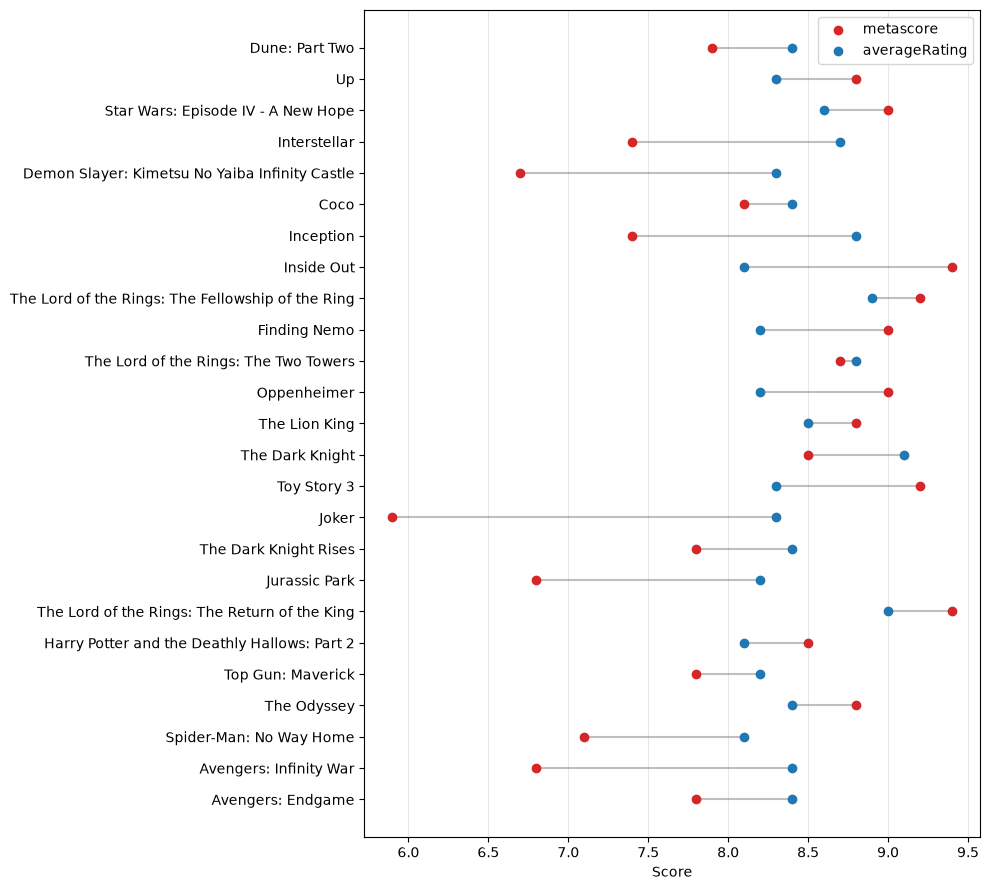

In [31]:
fig, ax = plt.subplots(figsize=(10, 9))
y = range(len(most_revenues))

# linea che collega i due punti
ax.hlines(y, most_revenues["metascore"]/10, most_revenues["averageRating"], color="gray", alpha=0.5)

# due punti per film
ax.scatter(most_revenues["metascore"]/10, y, color="tab:red", label="metascore", zorder=3)
ax.scatter(most_revenues["averageRating"], y, color="tab:blue", label="averageRating", zorder=3)

ax.set_yticks(list(y))
ax.set_yticklabels(most_revenues["primaryTitle"])
ax.set_xlabel("Score")
ax.legend()
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

the best score is not always the one from viewers or critique, does it is affected by any other detail?

## Does the public prefear a genere more than others?

In [32]:
# genres è una lista salvata come stringa: converti e crea una riga per genere
most_revenues["genres"] = most_revenues["genres"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
most_revenues = most_revenues.explode("genres")

# media per genere
by_genre = (most_revenues.assign(metascore=most_revenues["metascore"] / 10)
              .groupby("genres")
              .agg(metascore=("metascore", "mean"),
                   averageRating=("averageRating", "mean"),
                   n=("primaryTitle", "size"))
              .query("n >= 5")                      # soglia minima di film per genere
              .assign(diff=lambda d: d["averageRating"] - d["metascore"])
              .sort_values("diff"))

fig, ax = plt.subplots(figsize=(10, 9))
y = range(len(by_genre))

# linea che collega i due punti
ax.hlines(y, by_genre["metascore"], by_genre["averageRating"], color="gray", alpha=0.5)

# due punti per genere
ax.scatter(by_genre["metascore"], y, color="tab:red", label="metascore", zorder=3)
ax.scatter(by_genre["averageRating"], y, color="tab:blue", label="averageRating", zorder=3)

ax.set_yticks(list(y))
ax.set_yticklabels([f"{g} (n={n})" for g, n in zip(by_genre.index, by_genre["n"])])
ax.set_xlabel("Score medio")
ax.legend()
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'ast' is not defined